# 🏦 SKYC - Credit Card Fraud & PaySim Analysis
## Part 2: Training Models on Additional Datasets
---
### Al-Balqa Applied University | Faculty of Artificial Intelligence
### هاد الـ notebook بيطبق الموديلات الـ 3 supervised على الداتاسيتس:
- **Part A:** Credit Card Fraud Dataset
- **Part B:** PaySim Dataset
- **Part C:** المقارنة النهائية بين الـ 3 داتاسيتس (IBM AML + Credit Card + PaySim)
---

## 📚 1. Import Libraries

In [60]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, precision_score, recall_score, f1_score, accuracy_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

print('✅ All libraries imported successfully')

✅ All libraries imported successfully


---
# ═══════════════════════════════════════════
# 📗 PART A: Credit Card Fraud Dataset
# ═══════════════════════════════════════════
> **Dataset:** European credit card transactions
> **Size:** 284,807 transactions, 492 fraud cases (0.172%)
> **Features:** V1-V28 (PCA transformed) + Amount + Time + Class

## 📂 A.1 Load Credit Card Data

In [61]:
CC_FILE = '../../data/raw/creditcard.csv'

if os.path.exists(CC_FILE):
    df_cc = pd.read_csv(CC_FILE)
    print(f'✅ Loaded: {df_cc.shape}')
else:
    print(f'❌ File not found: {CC_FILE}')
    raise FileNotFoundError(CC_FILE)

print(f'\n📊 Dataset Info:')
print(f'  Total transactions: {len(df_cc):,}')
print(f'  Fraud cases:        {df_cc["Class"].sum():,}')
print(f'  Fraud rate:         {df_cc["Class"].mean():.4%}')
print(f'  Columns:            {df_cc.shape[1]}')

df_cc.head(50)

✅ Loaded: (284807, 31)

📊 Dataset Info:
  Total transactions: 284,807
  Fraud cases:        492
  Fraud rate:         0.1727%
  Columns:            31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


## 🔍 A.2 Data Exploration

In [62]:
print('Missing values:', df_cc.isnull().sum().sum())
print('\nClass distribution:')
print(df_cc['Class'].value_counts())
print(f'\nImbalance ratio: 1:{int((df_cc["Class"]==0).sum() / (df_cc["Class"]==1).sum())}')

Missing values: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Imbalance ratio: 1:577


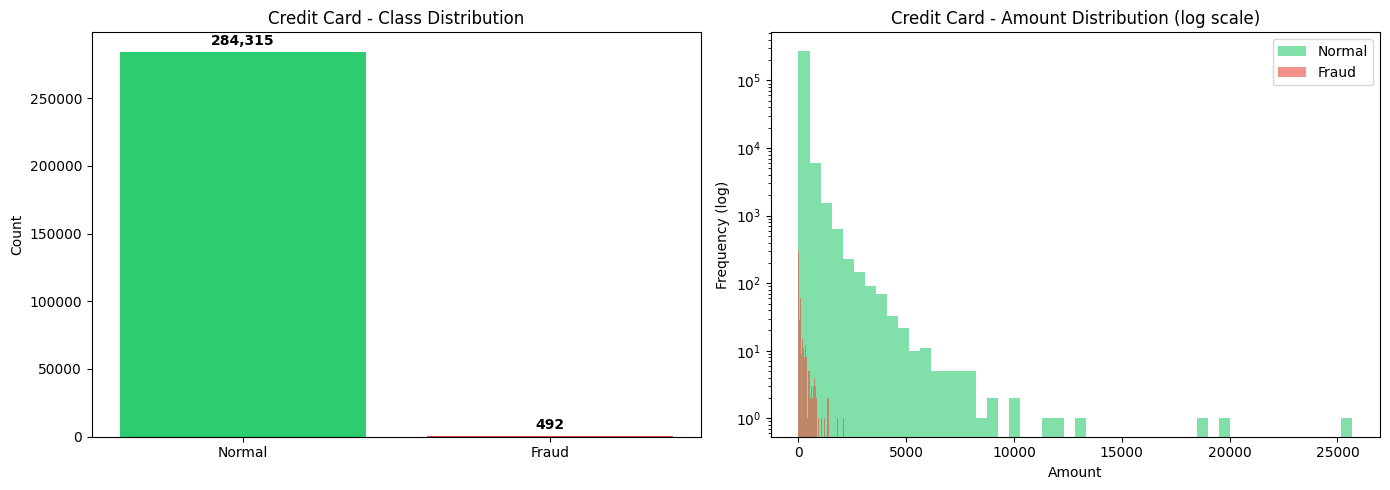

✅ Data exploration plots saved


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df_cc['Class'].value_counts()
axes[0].bar(['Normal', 'Fraud'], counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Credit Card - Class Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5000, f'{v:,}', ha='center', fontweight='bold')

axes[1].hist(df_cc[df_cc['Class']==0]['Amount'], bins=50, alpha=0.6, 
             label='Normal', color='#2ecc71', log=True)
axes[1].hist(df_cc[df_cc['Class']==1]['Amount'], bins=50, alpha=0.6, 
             label='Fraud', color='#e74c3c', log=True)
axes[1].set_title('Credit Card - Amount Distribution (log scale)')
axes[1].set_xlabel('Amount')
axes[1].set_ylabel('Frequency (log)')
axes[1].legend()

plt.tight_layout()
plt.savefig('cc_data_exploration.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Data exploration plots saved')

## 🎯 A.3 Stratified Sampling & Feature Selection
> : نأخذ عينة 30,000 باستخدام stratified sampling للحفاظ على نسبة الاحتيال

In [64]:
# ═══════════════════════════════════════════
# 🎯 Sampling: 30,000 مع الحفاظ على كل حالات الاحتيال
# ═══════════════════════════════════════════

fraud = df_cc[df_cc['Class'] == 1]                              # 492 كلهم
normal = df_cc[df_cc['Class'] == 0].sample(
    n=30000 - len(fraud), random_state=42                       # 29,508
)

df_cc_sample = pd.concat([fraud, normal])
df_cc_sample = df_cc_sample.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'✅ Sample size: {len(df_cc_sample):,}')
print(f'   Fraud:  {df_cc_sample["Class"].sum()} ({df_cc_sample["Class"].mean():.2%})')
print(f'   Normal: {(df_cc_sample["Class"]==0).sum()}')


✅ Sample size: 30,000
   Fraud:  492 (1.64%)
   Normal: 29508


In [65]:
CC_FEATURES = [f'V{i}' for i in range(1, 29)] + ['Amount']
CC_TARGET = 'Class'

X_cc = df_cc_sample[CC_FEATURES]
y_cc = df_cc_sample[CC_TARGET]

print(f'Features: {len(CC_FEATURES)}')
print(f'X shape: {X_cc.shape}')
print(f'y shape: {y_cc.shape}')


Features: 29
X shape: (30000, 29)
y shape: (30000,)


## 🔧 A.4 Preprocessing

In [66]:
X_cc_train, X_cc_test, y_cc_train, y_cc_test = train_test_split(
    X_cc, y_cc, test_size=0.2, random_state=42, stratify=y_cc
)

print(f'Train: {X_cc_train.shape} | Test: {X_cc_test.shape}')
print(f'Train fraud rate: {y_cc_train.mean():.4%}')
print(f'Test fraud rate:  {y_cc_test.mean():.4%}')

Train: (24000, 29) | Test: (6000, 29)
Train fraud rate: 1.6417%
Test fraud rate:  1.6333%


In [67]:
# ═══════════════════════════════════════════
#  Step 1: Scaling 
# ═══════════════════════════════════════════

scaler_cc = StandardScaler()
X_cc_train_scaled = scaler_cc.fit_transform(X_cc_train)
X_cc_test_scaled = scaler_cc.transform(X_cc_test)

print('✅ Scaling done')
print(f'X_cc_train_scaled: {X_cc_train_scaled.shape}')
print(f'X_cc_test_scaled: {X_cc_test_scaled.shape}')


✅ Scaling done
X_cc_train_scaled: (24000, 29)
X_cc_test_scaled: (6000, 29)


In [68]:
# ═══════════════════════════════════════════
#  Step 2: SMOTE 
# ═══════════════════════════════════════════

print('Applying SMOTE...')
print(f'Before SMOTE: {X_cc_train_scaled.shape}')
print(f'  Fraud: {y_cc_train.sum()} | Normal: {(y_cc_train==0).sum()}')

smote = SMOTE(random_state=42)
X_cc_train_res, y_cc_train_res = smote.fit_resample(X_cc_train_scaled, y_cc_train)

print(f'\nAfter SMOTE: {X_cc_train_res.shape}')
print(f'  Distribution: {pd.Series(y_cc_train_res).value_counts().to_dict()}')
print(f'\n✅ Test data unchanged: {X_cc_test_scaled.shape} (fraud: {y_cc_test.sum()})')


Applying SMOTE...
Before SMOTE: (24000, 29)
  Fraud: 394 | Normal: 23606

After SMOTE: (47212, 29)
  Distribution: {0: 23606, 1: 23606}

✅ Test data unchanged: (6000, 29) (fraud: 98)


## 🤖 A.5 Train 3 Models on Credit Card

In [104]:
# === Logistic Regression ===
LR_CC_PATH = 'lr_creditcard_model.pkl'

if os.path.exists(LR_CC_PATH):
    os.remove(LR_CC_PATH)

print('Training Logistic Regression on Credit Card...')
lr_cc = LogisticRegression(
    max_iter=1000, class_weight=None,
    C=1.0, penalty='l2', solver='lbfgs',
    random_state=42, n_jobs=-1
)
lr_cc.fit(X_cc_train_res, y_cc_train_res)
joblib.dump(lr_cc, LR_CC_PATH)
print('✅ LR saved')

lr_cc_pred  = lr_cc.predict(X_cc_test_scaled)
lr_cc_proba = lr_cc.predict_proba(X_cc_test_scaled)[:, 1]

print('\n📊 Logistic Regression Results (Credit Card):')
print(classification_report(y_cc_test, lr_cc_pred))
print(f'ROC-AUC: {roc_auc_score(y_cc_test, lr_cc_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_cc_test, lr_cc_proba):.4f}')


Training Logistic Regression on Credit Card...
✅ LR saved

📊 Logistic Regression Results (Credit Card):
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      5902
           1       0.42      0.91      0.58        98

    accuracy                           0.98      6000
   macro avg       0.71      0.94      0.78      6000
weighted avg       0.99      0.98      0.98      6000

ROC-AUC: 0.9793
PR-AUC:  0.9075


In [70]:
#  Overfitting Check — Logistic Regression (Credit Card)
print('============================================================')
print(' Overfitting Check — Logistic Regression')
print('============================================================')

train_proba_ov = lr_cc.predict_proba(X_cc_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_cc_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_cc_test, lr_cc_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print(f"   ✅ No Overfitting (less than 5%)")
elif gap_ov < 0.10:
    print(f"   🟡 Overfitting (between 5%-10%)")
else:
    print(f"   🔴 Overfitting (more than 10%)")
print('============================================================')


 Overfitting Check — Logistic Regression
  Train AUC: 0.9891
  Test AUC:  0.9793
  Gap:       0.0098
   ✅ No Overfitting (less than 5%)


In [71]:
#  5-Fold Cross Validation — Logistic Regression (Credit Card)
from sklearn.model_selection import StratifiedKFold

skf_lo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_cc_sample[CC_FEATURES].values
y_kf = df_cc_sample['Class'].values

kf_results_lo = []

print('============================================================')
print(' 5-Fold CV — Logistic Regression (Credit Card)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_lo.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = LogisticRegression(max_iter=1000, C=1.0, penalty='l2', solver='lbfgs', random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_lo.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_lo)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


 5-Fold CV — Logistic Regression (Credit Card)
  Fold 1: AUC=0.9740 | F1=0.5488 | Prec=0.3913 | Rec=0.9184
  Fold 2: AUC=0.9829 | F1=0.5322 | Prec=0.3730 | Rec=0.9286
  Fold 3: AUC=0.9742 | F1=0.5131 | Prec=0.3592 | Rec=0.8980
  Fold 4: AUC=0.9849 | F1=0.5444 | Prec=0.3849 | Rec=0.9293
  Fold 5: AUC=0.9725 | F1=0.5301 | Prec=0.3777 | Rec=0.8889

📊 Average:
   ROC-AUC     : 0.9777 ± 0.0057
   F1          : 0.5337 ± 0.0140
   Precision   : 0.3772 ± 0.0123
   Recall      : 0.9126 ± 0.0183

✅ مستقر جداً — لا يوجد overfitting


In [105]:
# === Random Forest ===
RF_CC_PATH = 'rf_creditcard_model.pkl'

if os.path.exists(RF_CC_PATH):
    os.remove(RF_CC_PATH)

print('Training Random Forest on Credit Card...')
rf_cc = RandomForestClassifier(
    n_estimators=200, max_depth=15,
    min_samples_leaf=5, class_weight=None,
    random_state=42, n_jobs=-1
)
rf_cc.fit(X_cc_train_res, y_cc_train_res)
joblib.dump(rf_cc, RF_CC_PATH)
print('✅ RF saved')

rf_cc_pred  = rf_cc.predict(X_cc_test_scaled)
rf_cc_proba = rf_cc.predict_proba(X_cc_test_scaled)[:, 1]

print('\n📊 Random Forest Results (Credit Card):')
print(classification_report(y_cc_test, rf_cc_pred))
print(f'ROC-AUC: {roc_auc_score(y_cc_test, rf_cc_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_cc_test, rf_cc_proba):.4f}')


Training Random Forest on Credit Card...
✅ RF saved

📊 Random Forest Results (Credit Card):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5902
           1       0.92      0.87      0.89        98

    accuracy                           1.00      6000
   macro avg       0.96      0.93      0.95      6000
weighted avg       1.00      1.00      1.00      6000

ROC-AUC: 0.9822
PR-AUC:  0.9272


In [73]:
#  Overfitting Check — Random Forest (Credit Card)
print('============================================================')
print(' Overfitting Check — Random Forest')
print('============================================================')

train_proba_ov = rf_cc.predict_proba(X_cc_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_cc_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_cc_test, rf_cc_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print(f"   ✅ No Overfitting (less than 5%)")
elif gap_ov < 0.10:
    print(f"   🟡 Overfitting (between 5%-10%)")
else:
    print(f"   🔴 Overfitting (more than 10%)")
print('============================================================')


 Overfitting Check — Random Forest
  Train AUC: 1.0000
  Test AUC:  0.9822
  Gap:       0.0178
   ✅ No Overfitting (less than 5%)


In [74]:
#  5-Fold Cross Validation — Random Forest (Credit Card)
from sklearn.model_selection import StratifiedKFold

skf_ra = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_cc_sample[CC_FEATURES].values
y_kf = df_cc_sample['Class'].values

kf_results_ra = []

print('============================================================')
print(' 5-Fold CV — Random Forest (Credit Card)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_ra.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5, random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_ra.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_ra)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


 5-Fold CV — Random Forest (Credit Card)
  Fold 1: AUC=0.9825 | F1=0.8947 | Prec=0.9239 | Rec=0.8673
  Fold 2: AUC=0.9920 | F1=0.9082 | Prec=0.9082 | Rec=0.9082
  Fold 3: AUC=0.9746 | F1=0.8466 | Prec=0.8791 | Rec=0.8163
  Fold 4: AUC=0.9887 | F1=0.8844 | Prec=0.8800 | Rec=0.8889
  Fold 5: AUC=0.9836 | F1=0.8889 | Prec=0.9333 | Rec=0.8485

📊 Average:
   ROC-AUC     : 0.9843 ± 0.0066
   F1          : 0.8846 ± 0.0230
   Precision   : 0.9049 ± 0.0248
   Recall      : 0.8658 ± 0.0356

✅ مستقر جداً — لا يوجد overfitting


In [75]:
# === XGBoost ===
XGB_CC_PATH = 'xgb_creditcard_model.pkl'

if os.path.exists(XGB_CC_PATH):
    os.remove(XGB_CC_PATH)

print('Training XGBoost on Credit Card...')
xgb_cc = XGBClassifier(
    n_estimators=200, max_depth=8,
    learning_rate=0.05, eval_metric='logloss',
    random_state=42, n_jobs=-1
)
xgb_cc.fit(X_cc_train_res, y_cc_train_res)
joblib.dump(xgb_cc, XGB_CC_PATH)
print('✅ XGBoost saved')

xgb_cc_pred  = xgb_cc.predict(X_cc_test_scaled)
xgb_cc_proba = xgb_cc.predict_proba(X_cc_test_scaled)[:, 1]

print('\n📊 XGBoost Results (Credit Card):')
print(classification_report(y_cc_test, xgb_cc_pred))
print(f'ROC-AUC: {roc_auc_score(y_cc_test, xgb_cc_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_cc_test, xgb_cc_proba):.4f}')


Training XGBoost on Credit Card...
✅ XGBoost saved

📊 XGBoost Results (Credit Card):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5902
           1       0.87      0.89      0.88        98

    accuracy                           1.00      6000
   macro avg       0.93      0.94      0.94      6000
weighted avg       1.00      1.00      1.00      6000

ROC-AUC: 0.9826
PR-AUC:  0.9147


In [76]:
#  Overfitting Check — XGBoost (Credit Card)
print('============================================================')
print(' Overfitting Check — XGBoost')
print('============================================================')

train_proba_ov = xgb_cc.predict_proba(X_cc_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_cc_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_cc_test, xgb_cc_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print(f"   ✅ No Overfitting (less than 5%)")
elif gap_ov < 0.10:
    print(f"   🟡 Overfitting (between 5%-10%)")
else:
    print(f"   🔴 Overfitting (more than 10%)")
print('============================================================')


 Overfitting Check — XGBoost
  Train AUC: 1.0000
  Test AUC:  0.9826
  Gap:       0.0174
   ✅ No Overfitting (less than 5%)


In [77]:
# 🔄 5-Fold Cross Validation — XGBoost (Credit Card)
from sklearn.model_selection import StratifiedKFold

skf_xg = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_cc_sample[CC_FEATURES].values
y_kf = df_cc_sample['Class'].values

kf_results_xg = []

print('============================================================')
print('🔄 5-Fold CV — XGBoost (Credit Card)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_xg.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.05, eval_metric='logloss', random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_xg.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_xg)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


🔄 5-Fold CV — XGBoost (Credit Card)
  Fold 1: AUC=0.9785 | F1=0.8426 | Prec=0.8384 | Rec=0.8469
  Fold 2: AUC=0.9909 | F1=0.8821 | Prec=0.8866 | Rec=0.8776
  Fold 3: AUC=0.9657 | F1=0.8000 | Prec=0.7843 | Rec=0.8163
  Fold 4: AUC=0.9891 | F1=0.8502 | Prec=0.8148 | Rec=0.8889
  Fold 5: AUC=0.9782 | F1=0.8485 | Prec=0.8485 | Rec=0.8485

📊 Average:
   ROC-AUC     : 0.9805 ± 0.0101
   F1          : 0.8447 ± 0.0293
   Precision   : 0.8345 ± 0.0382
   Recall      : 0.8556 ± 0.0285

✅ مستقر جداً — لا يوجد overfitting


## 📊 A.6 Credit Card - Comparison & Visualization

In [78]:
# Credit Card Results Summary
cc_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Precision': [
        precision_score(y_cc_test, lr_cc_pred),
        precision_score(y_cc_test, rf_cc_pred),
        precision_score(y_cc_test, xgb_cc_pred)
    ],
    'Recall': [
        recall_score(y_cc_test, lr_cc_pred),
        recall_score(y_cc_test, rf_cc_pred),
        recall_score(y_cc_test, xgb_cc_pred)
    ],
    'F1-Score': [
        f1_score(y_cc_test, lr_cc_pred),
        f1_score(y_cc_test, rf_cc_pred),
        f1_score(y_cc_test, xgb_cc_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_cc_test, lr_cc_proba),
        roc_auc_score(y_cc_test, rf_cc_proba),
        roc_auc_score(y_cc_test, xgb_cc_proba)
    ],
    'PR-AUC': [
        average_precision_score(y_cc_test, lr_cc_proba),
        average_precision_score(y_cc_test, rf_cc_proba),
        average_precision_score(y_cc_test, xgb_cc_proba)
    ]
}).round(4)

print('\n' + '='*70)
print(' Credit Card Fraud - Model Comparison')
print('='*70)
print(cc_summary.to_string(index=False))
print('='*70)


 Credit Card Fraud - Model Comparison
              Model  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression     0.4238  0.9082    0.5779   0.9793  0.9075
      Random Forest     0.9239  0.8673    0.8947   0.9822  0.9272
            XGBoost     0.8700  0.8878    0.8788   0.9826  0.9147


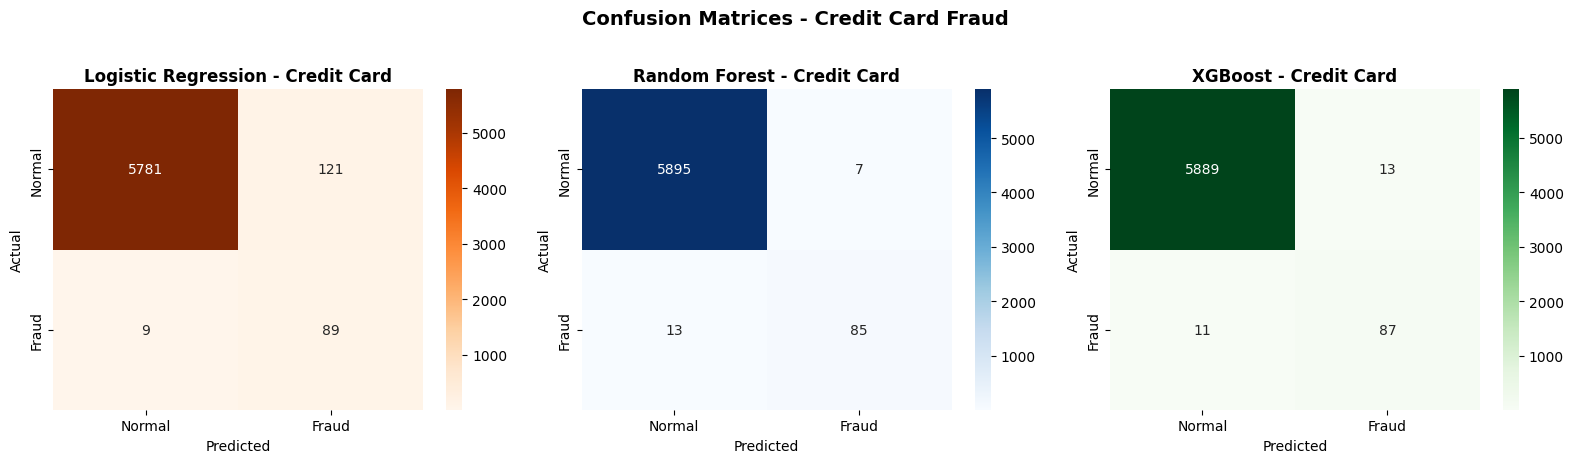

✅ Confusion Matrices saved


In [79]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cc_models = [
    (lr_cc_pred, 'Logistic Regression', 'Oranges'),
    (rf_cc_pred, 'Random Forest', 'Blues'),
    (xgb_cc_pred, 'XGBoost', 'Greens')
]
for ax, (pred, title, cmap) in zip(axes, cc_models):
    cm = confusion_matrix(y_cc_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Normal', 'Fraud'],
                yticklabels=['Normal', 'Fraud'])
    ax.set_title(f'{title} - Credit Card', fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrices - Credit Card Fraud', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('cc_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Confusion Matrices saved')

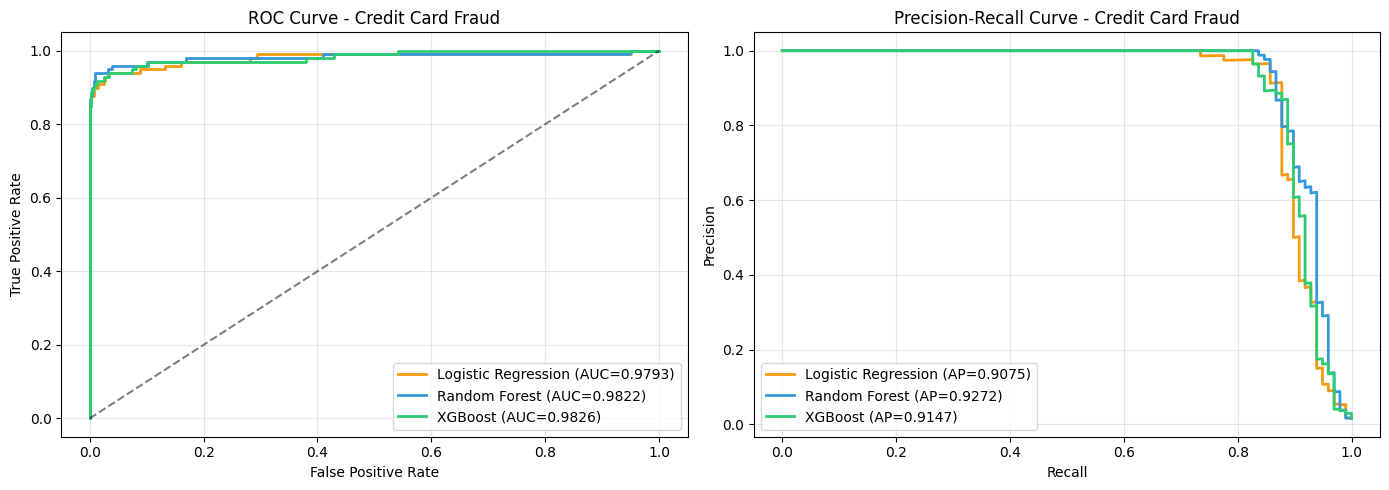

✅ ROC & PR Curves saved


In [80]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cc_probas = [
    (lr_cc_proba, 'Logistic Regression', '#f39c12'),
    (rf_cc_proba, 'Random Forest', '#3498db'),
    (xgb_cc_proba, 'XGBoost', '#2ecc71')
]

# ROC
ax = axes[0]
for proba, label, color in cc_probas:
    fpr, tpr, _ = roc_curve(y_cc_test, proba)
    auc = roc_auc_score(y_cc_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{label} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Credit Card Fraud')
ax.legend()
ax.grid(alpha=0.3)

# PR
ax = axes[1]
for proba, label, color in cc_probas:
    precision_vals, recall_vals, _ = precision_recall_curve(y_cc_test, proba)
    ap = average_precision_score(y_cc_test, proba)
    ax.plot(recall_vals, precision_vals, color=color, linewidth=2, label=f'{label} (AP={ap:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve - Credit Card Fraud')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('cc_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ ROC & PR Curves saved')

---
# ═══════════════════════════════════════════
# 📘 PART B: PaySim Dataset
# ═══════════════════════════════════════════
> **Dataset:** Mobile money simulation transactions
> **Original size:** ~6M transactions | **Sampled:** 50,000
> **Features:** type, amount, sender/receiver balances, fraud labels

## 📂 B.1 Load PaySim Data

In [81]:
PS_FILE = "../../data/raw/paysim.csv"

if os.path.exists(PS_FILE):
    print(f'Loading {PS_FILE}...')
  
    df_ps = pd.read_csv(PS_FILE)
    print(f'✅ Loaded: {df_ps.shape}')
else:
    print(f'❌ File not found: {PS_FILE}')
    raise FileNotFoundError(PS_FILE)

print(f'\n📊 Dataset Info:')
print(f'  Total transactions: {len(df_ps):,}')
print(f'  Fraud cases:        {df_ps["isFraud"].sum():,}')
print(f'  Fraud rate:         {df_ps["isFraud"].mean():.4%}')
print(f'  Columns:            {df_ps.shape[1]}')

df_ps.head(100)

Loading ../../data/raw/paysim.csv...
✅ Loaded: (6362620, 11)

📊 Dataset Info:
  Total transactions: 6,362,620
  Fraud cases:        8,213
  Fraud rate:         0.1291%
  Columns:            11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
95,1,TRANSFER,710544.77,C835773569,0.0,0.00,C1359044626,738531.50,16518.36,0,0
96,1,TRANSFER,581294.26,C843299092,0.0,0.00,C1590550415,5195482.15,19169204.93,0,0
97,1,TRANSFER,11996.58,C605982374,0.0,0.00,C1225616405,40255.00,0.00,0,0
98,1,PAYMENT,2875.10,C1412322831,15443.0,12567.90,M1651262695,0.00,0.00,0,0


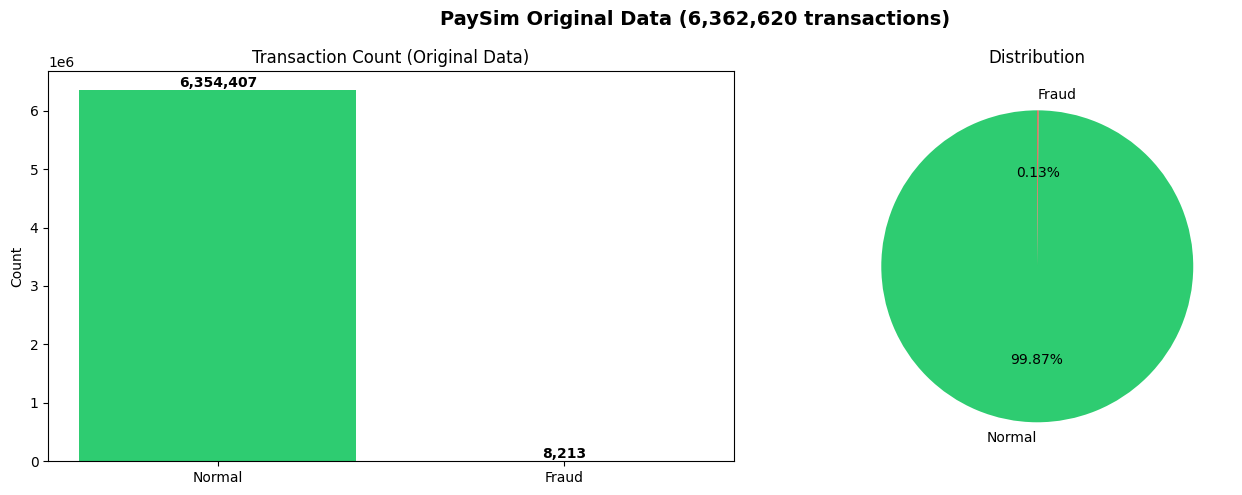


📊 Original Data Stats:
  Total: 6,362,620
  Normal: 6,354,407 (99.87%)
  Fraud: 8,213 (0.1291%)

📊 Fraud by type:
            count   sum    mean
type                           
CASH_IN   1399284     0  0.0000
CASH_OUT  2237500  4116  0.0018
DEBIT       41432     0  0.0000
PAYMENT   2151495     0  0.0000
TRANSFER   532909  4097  0.0077


In [82]:
# ═══════════════════════════════════════════
# 📊 PaySim - EDA (قبل أخذ العينة - الداتا الأصلية)
# ═══════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. توزيع Normal vs Fraud
ax = axes[0]
counts = df_ps['isFraud'].value_counts()
ax.bar(['Normal', 'Fraud'], counts.values, color=['#2ecc71', '#e74c3c'])
ax.set_title('Transaction Count (Original Data)')
ax.set_ylabel('Count')
for i, v in enumerate(counts.values):
    ax.text(i, v + 50000, f'{v:,}', ha='center', fontweight='bold')

# 2. نسبة الاحتيال
ax = axes[1]
ax.pie(counts.values, labels=['Normal', 'Fraud'], 
       colors=['#2ecc71', '#e74c3c'], autopct='%1.2f%%', startangle=90)
ax.set_title('Distribution')

plt.suptitle(f'PaySim Original Data ({len(df_ps):,} transactions)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# إحصائيات
print(f'\n📊 Original Data Stats:')
print(f'  Total: {len(df_ps):,}')
print(f'  Normal: {(df_ps["isFraud"]==0).sum():,} ({(df_ps["isFraud"]==0).mean():.2%})')
print(f'  Fraud: {df_ps["isFraud"].sum():,} ({df_ps["isFraud"].mean():.4%})')
print(f'\n📊 Fraud by type:')
print(df_ps.groupby('type')['isFraud'].agg(['count', 'sum', 'mean']).round(4))

In [83]:
df_ps.shape

(6362620, 11)

In [84]:
print("Fraud count per transaction type:")
print(df_ps.groupby('type')['isFraud'].sum())

Fraud count per transaction type:
type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64


In [85]:
print('Transaction types:')
print(df_ps['type'].value_counts())
print('\nFraud rate per type:')
print(df_ps.groupby('type')['isFraud'].agg(['sum', 'mean']).round(4))

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Fraud rate per type:
           sum    mean
type                  
CASH_IN      0  0.0000
CASH_OUT  4116  0.0018
DEBIT        0  0.0000
PAYMENT      0  0.0000
TRANSFER  4097  0.0077


## 🎯 B.2 Sample 30,000 with Balanced Fraud

In [86]:
fraud_transactions = df_ps[df_ps['isFraud'] == 1]
normal_transactions = df_ps[df_ps['isFraud'] == 0]

print(f'Fraud: {len(fraud_transactions):,}')
print(f'Normal: {len(normal_transactions):,}')

n_fraud = len(fraud_transactions)
n_normal = 30000 - n_fraud

normal_sample = normal_transactions.sample(n=n_normal, random_state=42)
df_ps_sample = pd.concat([fraud_transactions, normal_sample], ignore_index=True)
df_ps_sample = df_ps_sample.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\n✅ Sample: {len(df_ps_sample):,}')
print(f'   Fraud: {df_ps_sample["isFraud"].sum():,} ({df_ps_sample["isFraud"].mean():.2%})')
print(f'   Normal: {(df_ps_sample["isFraud"]==0).sum():,}')


Fraud: 8,213
Normal: 6,354,407

✅ Sample: 30,000
   Fraud: 8,213 (27.38%)
   Normal: 21,787


In [87]:
#التأكد من وجود كل الانواع بعد ال sampling
print("📊 Transaction types in the sample:")
print(df_ps_sample.groupby(['type', 'isFraud']).size().unstack(fill_value=0))

print("\n📊 Percentage per type:")
print(df_ps_sample['type'].value_counts())
print(f"\nTotal types: {df_ps_sample['type'].nunique()}")

📊 Transaction types in the sample:
isFraud      0     1
type                
CASH_IN   4784     0
CASH_OUT  7727  4116
DEBIT      135     0
PAYMENT   7355     0
TRANSFER  1786  4097

📊 Percentage per type:
type
CASH_OUT    11843
PAYMENT      7355
TRANSFER     5883
CASH_IN      4784
DEBIT         135
Name: count, dtype: int64

Total types: 5


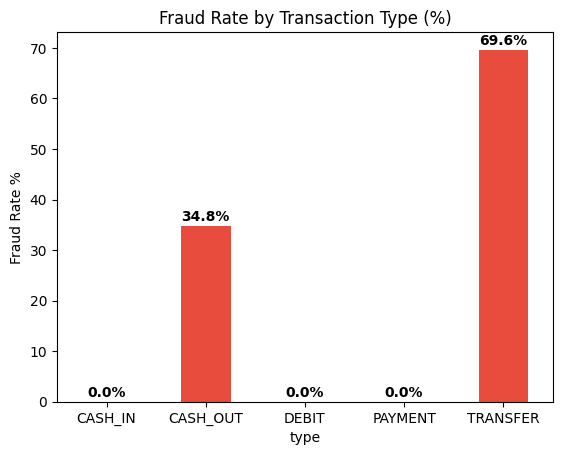

In [88]:
# 1. نسبة الاحتيال حسب نوع المعاملة
fraud_by_type = df_ps_sample.groupby('type')['isFraud'].mean() * 100
fraud_by_type.plot(kind='bar', color=['#2ecc71' if v < 10 else '#e74c3c' for v in fraud_by_type.values])
plt.title('Fraud Rate by Transaction Type (%)')
plt.ylabel('Fraud Rate %')
plt.xticks(rotation=0)
for i, v in enumerate(fraud_by_type.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
plt.show()

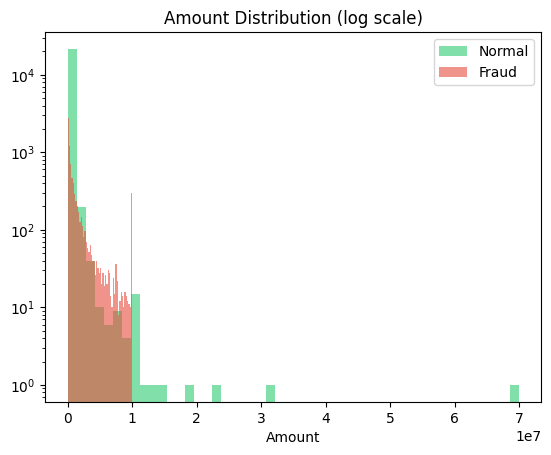

In [89]:
# 2. توزيع المبالغ (طبيعي vs احتيال)
plt.hist(df_ps_sample[df_ps_sample['isFraud']==0]['amount'], bins=50, alpha=0.6, 
         label='Normal', color='#2ecc71', log=True)
plt.hist(df_ps_sample[df_ps_sample['isFraud']==1]['amount'], bins=50, alpha=0.6, 
         label='Fraud', color='#e74c3c', log=True)
plt.title('Amount Distribution (log scale)')
plt.xlabel('Amount')
plt.legend()
plt.show()

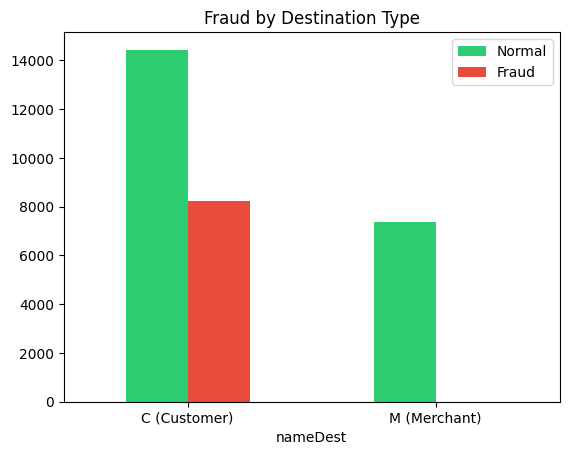

In [90]:
# 3. المستقبل عميل أو تاجر
dest_type = df_ps_sample.groupby([df_ps_sample['nameDest'].str[0], 'isFraud']).size().unstack(fill_value=0)
dest_type.plot(kind='bar', color=['#2ecc71', '#e74c3c'])
plt.title('Fraud by Destination Type')
plt.xticks([0, 1], ['C (Customer)', 'M (Merchant)'], rotation=0)
plt.legend(['Normal', 'Fraud'])
plt.show()

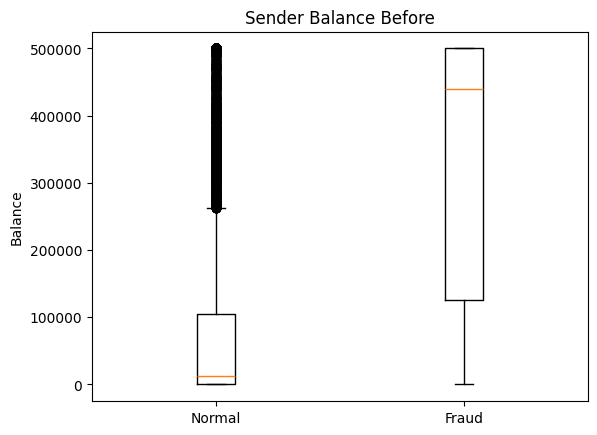

In [91]:
# 4. رصيد المرسل قبل (طبيعي vs احتيال)
plt.boxplot([
    df_ps_sample[df_ps_sample['isFraud']==0]['oldbalanceOrg'].clip(0, 500000),
    df_ps_sample[df_ps_sample['isFraud']==1]['oldbalanceOrg'].clip(0, 500000)
], labels=['Normal', 'Fraud'])
plt.title('Sender Balance Before')
plt.ylabel('Balance')
plt.show()

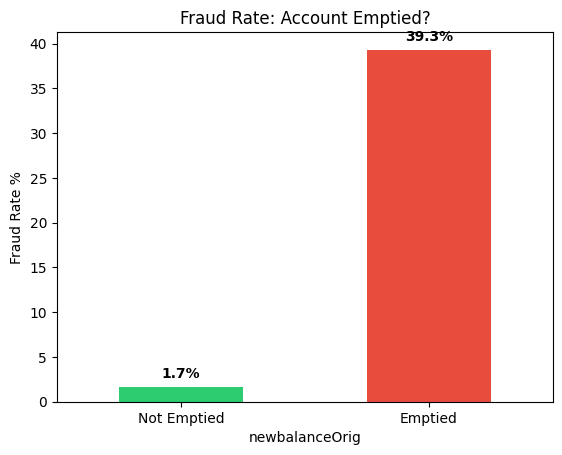

In [92]:
# 5. هل فرّغ الحساب؟
emptied = (df_ps_sample['newbalanceOrig'] == 0).astype(int)
emptied_fraud = df_ps_sample.groupby(emptied)['isFraud'].mean() * 100
emptied_fraud.plot(kind='bar', color=['#2ecc71', '#e74c3c'])
plt.title('Fraud Rate: Account Emptied?')
plt.xticks([0, 1], ['Not Emptied', 'Emptied'], rotation=0)
plt.ylabel('Fraud Rate %')
for i, v in enumerate(emptied_fraud.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
plt.show()

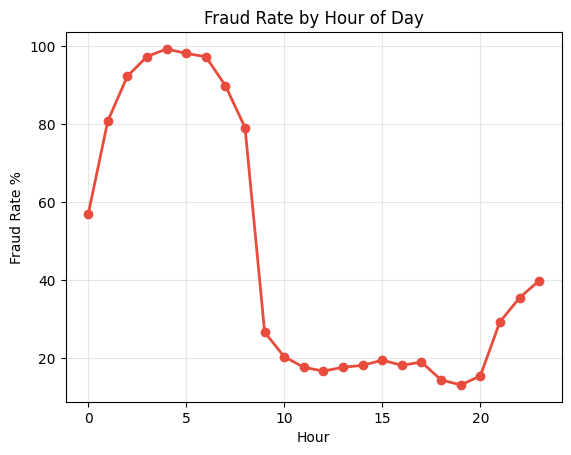

In [93]:
# 6. الاحتيال حسب الساعة
hour = df_ps_sample['step'] % 24
hour_fraud = df_ps_sample.groupby(hour)['isFraud'].mean() * 100
plt.plot(hour_fraud.index, hour_fraud.values, color='#e74c3c', linewidth=2, marker='o')
plt.title('Fraud Rate by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate %')
plt.grid(alpha=0.3)
plt.show()

## 🔧 B.3 Feature Engineering & Preprocessing

In [94]:
# ═══════════════════════════════════════════
# 📋 PaySim — Basic Features (بدون Feature Engineering)
# ═══════════════════════════════════════════

# One-Hot Encoding للنوع
type_encoded = pd.get_dummies(df_ps_sample['type'], prefix='type').astype(int)
df_ps_sample = pd.concat([df_ps_sample, type_encoded], axis=1)

# نستخدم الأعمدة الأصلية + نوع المعاملة فقط — بدون features محسوبة
PS_FEATURES = [
    'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest',
] + list(type_encoded.columns)

PS_TARGET = 'isFraud'

X_ps = df_ps_sample[PS_FEATURES]
y_ps = df_ps_sample[PS_TARGET]

print(f'Features: {len(PS_FEATURES)} (أصلية + نوع المعاملة — بدون Feature Engineering)')
print(f'X shape: {X_ps.shape}')
print(f'\nFeatures list:')
for i, feat in enumerate(PS_FEATURES, 1):
    print(f'  {i}. {feat}')

Features: 10 (أصلية + نوع المعاملة — بدون Feature Engineering)
X shape: (30000, 10)

Features list:
  1. amount
  2. oldbalanceOrg
  3. newbalanceOrig
  4. oldbalanceDest
  5. newbalanceDest
  6. type_CASH_IN
  7. type_CASH_OUT
  8. type_DEBIT
  9. type_PAYMENT
  10. type_TRANSFER


In [95]:
print("isFlaggedFraud = 1 حالات:")
flagged = df_ps_sample[df_ps_sample['isFlaggedFraud'] == 1]
print(f"العدد: {len(flagged)}")
print(f"\nالأنواع:")
print(flagged['type'].value_counts())
print(f"\nأقل مبلغ: {flagged['amount'].min():,.0f}")
print(f"أكبر مبلغ: {flagged['amount'].max():,.0f}")

isFlaggedFraud = 1 حالات:
العدد: 16

الأنواع:
type
TRANSFER    16
Name: count, dtype: int64

أقل مبلغ: 353,874
أكبر مبلغ: 10,000,000


In [96]:
print(f"بالداتا الأصلية (6 مليون):")
print(f"  isFlaggedFraud = 1: {df_ps['isFlaggedFraud'].sum()}")
print(f"  إجمالي الاحتيال: {df_ps['isFraud'].sum()}")
print(f"  نسبة الكشف: {df_ps['isFlaggedFraud'].sum() / df_ps['isFraud'].sum():.2%}")

بالداتا الأصلية (6 مليون):
  isFlaggedFraud = 1: 16
  إجمالي الاحتيال: 8213
  نسبة الكشف: 0.19%


In [97]:
flagged = df_ps_sample[df_ps_sample['isFlaggedFraud'] == 1]

print(f"isFlaggedFraud = 1: {len(flagged)} معاملة")
print(f"\nمنهم فعلاً احتيال (isFraud = 1): {flagged['isFraud'].sum()}")
print(f"منهم طبيعي (isFraud = 0): {(flagged['isFraud'] == 0).sum()}")
print(f"\nدقة النظام القديم: {flagged['isFraud'].mean():.2%}")

isFlaggedFraud = 1: 16 معاملة

منهم فعلاً احتيال (isFraud = 1): 16
منهم طبيعي (isFraud = 0): 0

دقة النظام القديم: 100.00%


In [98]:
X_ps_train, X_ps_test, y_ps_train, y_ps_test = train_test_split(
    X_ps, y_ps, test_size=0.2, random_state=42, stratify=y_ps
)

print(f'Train: {X_ps_train.shape} | Test: {X_ps_test.shape}')
print(f'Train fraud rate: {y_ps_train.mean():.4%}')
print(f'Test fraud rate:  {y_ps_test.mean():.4%}')

Train: (24000, 10) | Test: (6000, 10)
Train fraud rate: 27.3750%
Test fraud rate:  27.3833%


In [99]:
# Scaling
scaler_ps = StandardScaler()
X_ps_train_scaled = scaler_ps.fit_transform(X_ps_train)
X_ps_test_scaled = scaler_ps.transform(X_ps_test)

print('✅ Scaling done')

# SMOTE
print('Applying SMOTE...')
smote = SMOTE(random_state=42)
X_ps_train_res, y_ps_train_res = smote.fit_resample(X_ps_train_scaled, y_ps_train)
print(f'After SMOTE: {X_ps_train_res.shape}')
print(f'Distribution: {pd.Series(y_ps_train_res).value_counts().to_dict()}')

✅ Scaling done
Applying SMOTE...
After SMOTE: (34860, 10)
Distribution: {0: 17430, 1: 17430}


In [100]:
import os
for f in ['lr_paysim_model.pkl', 'rf_paysim_model.pkl', 'xgb_paysim_model.pkl']:
    if os.path.exists(f):
        os.remove(f)
        print(f"🗑️ Deleted: {f}")
print("✅ Old models deleted — شغّلي الموديلات من جديد")

🗑️ Deleted: lr_paysim_model.pkl
🗑️ Deleted: rf_paysim_model.pkl
🗑️ Deleted: xgb_paysim_model.pkl
✅ Old models deleted — شغّلي الموديلات من جديد


## 🤖 B.4 Train 3 Models on PaySim

In [102]:
# === Logistic Regression ===
LR_PS_PATH = 'lr_paysim_model.pkl'

if not os.path.exists(LR_PS_PATH):
    print('Training Logistic Regression on PaySim...')
    lr_ps = LogisticRegression(
        max_iter=1000, class_weight=None,
        C=1.0, penalty='l2', solver='lbfgs',
        random_state=42, n_jobs=-1
    )
    lr_ps.fit(X_ps_train_res, y_ps_train_res)
    joblib.dump(lr_ps, LR_PS_PATH)
    print('✅ LR saved')
else:
    lr_ps = joblib.load(LR_PS_PATH)
    print('⚡ LR loaded from cache')

lr_ps_pred  = lr_ps.predict(X_ps_test_scaled)
lr_ps_proba = lr_ps.predict_proba(X_ps_test_scaled)[:, 1]

print('\n Logistic Regression Results (PaySim):')
print(classification_report(y_ps_test, lr_ps_pred))
print(f'ROC-AUC: {roc_auc_score(y_ps_test, lr_ps_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_ps_test, lr_ps_proba):.4f}')

Training Logistic Regression on PaySim...
✅ LR saved

 Logistic Regression Results (PaySim):
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      4357
           1       0.87      0.92      0.89      1643

    accuracy                           0.94      6000
   macro avg       0.92      0.93      0.92      6000
weighted avg       0.94      0.94      0.94      6000

ROC-AUC: 0.9874
PR-AUC:  0.9707


In [ ]:
#  Overfitting Check — Logistic Regression (PaySim)
print('============================================================')
print(' Overfitting Check — Logistic Regression')
print('============================================================')

train_proba_ov = lr_ps.predict_proba(X_ps_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_ps_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_ps_test, lr_ps_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print('  ✅ لا يوجد Overfitting (الفرق أقل من 5%)')
elif gap_ov < 0.10:
    print('  🟡 Overfitting خفيف (الفرق 5-10%)')
else:
    print('  🔴 Overfitting واضح! (الفرق أكبر من 10%)')
print('============================================================')


 Overfitting Check — Logistic Regression
  Train AUC: 0.9868
  Test AUC:  0.9874
  Gap:       -0.0005
  ✅ لا يوجد Overfitting (الفرق أقل من 5%)


In [ ]:
# 🔄 5-Fold Cross Validation — Logistic Regression (PaySim)
from sklearn.model_selection import StratifiedKFold

skf_lo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_ps_sample[PS_FEATURES].values
y_kf = df_ps_sample['isFraud'].values

kf_results_lo = []

print('============================================================')
print('🔄 5-Fold CV — Logistic Regression (PaySim)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_lo.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = LogisticRegression(max_iter=1000, C=1.0, penalty='l2', solver='lbfgs', random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_lo.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_lo)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


🔄 5-Fold CV — Logistic Regression (PaySim)
  Fold 1: AUC=0.9863 | F1=0.8823 | Prec=0.8541 | Rec=0.9124
  Fold 2: AUC=0.9864 | F1=0.8912 | Prec=0.8688 | Rec=0.9148
  Fold 3: AUC=0.9868 | F1=0.8902 | Prec=0.8620 | Rec=0.9203
  Fold 4: AUC=0.9879 | F1=0.8903 | Prec=0.8463 | Rec=0.9391
  Fold 5: AUC=0.9850 | F1=0.8788 | Prec=0.8498 | Rec=0.9099

📊 Average:
   ROC-AUC     : 0.9865 ± 0.0010
   F1          : 0.8866 ± 0.0056
   Precision   : 0.8562 ± 0.0091
   Recall      : 0.9193 ± 0.0117

✅ مستقر جداً — لا يوجد overfitting


In [103]:
# === Random Forest ===
RF_PS_PATH = 'rf_paysim_model.pkl'

if not os.path.exists(RF_PS_PATH):
    print('Training Random Forest on PaySim...')
    rf_ps = RandomForestClassifier(
        n_estimators=100,
         class_weight=None,
        random_state=42
    )
    rf_ps.fit(X_ps_train_res, y_ps_train_res)
    joblib.dump(rf_ps, RF_PS_PATH)
    print('✅ RF saved')
else:
    rf_ps = joblib.load(RF_PS_PATH)
    print('⚡ RF loaded from cache')

rf_ps_pred  = rf_ps.predict(X_ps_test_scaled)
rf_ps_proba = rf_ps.predict_proba(X_ps_test_scaled)[:, 1]

print('\n Random Forest Results (PaySim):')
print(classification_report(y_ps_test, rf_ps_pred))
print(f'ROC-AUC: {roc_auc_score(y_ps_test, rf_ps_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_ps_test, rf_ps_proba):.4f}')

Training Random Forest on PaySim...
✅ RF saved

 Random Forest Results (PaySim):
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4357
           1       0.99      1.00      0.99      1643

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       0.99      0.99      0.99      6000

ROC-AUC: 0.9990
PR-AUC:  0.9981


In [ ]:
# 🔍 Overfitting Check — Random Forest (PaySim)
print('============================================================')
print('🔍 Overfitting Check — Random Forest')
print('============================================================')

train_proba_ov = rf_ps.predict_proba(X_ps_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_ps_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_ps_test, rf_ps_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print('  ✅ لا يوجد Overfitting (الفرق أقل من 5%)')
elif gap_ov < 0.10:
    print('  🟡 Overfitting خفيف (الفرق 5-10%)')
else:
    print('  🔴 Overfitting واضح! (الفرق أكبر من 10%)')
print('============================================================')


🔍 Overfitting Check — Random Forest
  Train AUC: 1.0000
  Test AUC:  0.9990
  Gap:       0.0010
  ✅ لا يوجد Overfitting (الفرق أقل من 5%)


In [ ]:
# 🔄 5-Fold Cross Validation — Random Forest (PaySim)
from sklearn.model_selection import StratifiedKFold

skf_ra = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_ps_sample[PS_FEATURES].values
y_kf = df_ps_sample['isFraud'].values

kf_results_ra = []

print('============================================================')
print('🔄 5-Fold CV — Random Forest (PaySim)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_ra.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5, random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_ra.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_ra)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


🔄 5-Fold CV — Random Forest (PaySim)
  Fold 1: AUC=0.9992 | F1=0.9846 | Prec=0.9749 | Rec=0.9945
  Fold 2: AUC=0.9990 | F1=0.9844 | Prec=0.9715 | Rec=0.9976
  Fold 3: AUC=0.9992 | F1=0.9825 | Prec=0.9737 | Rec=0.9915
  Fold 4: AUC=0.9992 | F1=0.9861 | Prec=0.9756 | Rec=0.9970
  Fold 5: AUC=0.9994 | F1=0.9811 | Prec=0.9663 | Rec=0.9963

📊 Average:
   ROC-AUC     : 0.9992 ± 0.0001
   F1          : 0.9838 ± 0.0020
   Precision   : 0.9724 ± 0.0037
   Recall      : 0.9954 ± 0.0025

✅ مستقر جداً — لا يوجد overfitting


In [ ]:
# === XGBoost ===
XGB_PS_PATH = 'xgb_paysim_model.pkl'

if not os.path.exists(XGB_PS_PATH):
    print('Training XGBoost on PaySim...')
    xgb_ps = XGBClassifier(
        n_estimators=200, max_depth=8,
        learning_rate=0.05, eval_metric='logloss',
        random_state=42, n_jobs=-1
    )
    xgb_ps.fit(X_ps_train_res, y_ps_train_res)
    joblib.dump(xgb_ps, XGB_PS_PATH)
    print('✅ XGBoost saved')
else:
    xgb_ps = joblib.load(XGB_PS_PATH)
    print('⚡ XGBoost loaded from cache')

xgb_ps_pred  = xgb_ps.predict(X_ps_test_scaled)
xgb_ps_proba = xgb_ps.predict_proba(X_ps_test_scaled)[:, 1]

print('\n XGBoost Results (PaySim):')
print(classification_report(y_ps_test, xgb_ps_pred))
print(f'ROC-AUC: {roc_auc_score(y_ps_test, xgb_ps_proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_ps_test, xgb_ps_proba):.4f}')

Training XGBoost on PaySim...
✅ XGBoost saved

 XGBoost Results (PaySim):
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4357
           1       0.98      0.99      0.99      1643

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       0.99      0.99      0.99      6000

ROC-AUC: 0.9990
PR-AUC:  0.9981


In [ ]:
# 🔍 Overfitting Check — XGBoost (PaySim)
print('============================================================')
print('🔍 Overfitting Check — XGBoost')
print('============================================================')

train_proba_ov = xgb_ps.predict_proba(X_ps_train_res)[:, 1]
train_auc_ov = roc_auc_score(y_ps_train_res, train_proba_ov)
test_auc_ov = roc_auc_score(y_ps_test, xgb_ps_proba)
gap_ov = train_auc_ov - test_auc_ov

print(f'  Train AUC: {train_auc_ov:.4f}')
print(f'  Test AUC:  {test_auc_ov:.4f}')
print(f'  Gap:       {gap_ov:.4f}')

if gap_ov < 0.05:
    print('  ✅ لا يوجد Overfitting (الفرق أقل من 5%)')
elif gap_ov < 0.10:
    print('  🟡 Overfitting خفيف (الفرق 5-10%)')
else:
    print('  🔴 Overfitting واضح! (الفرق أكبر من 10%)')
print('============================================================')


🔍 Overfitting Check — XGBoost
  Train AUC: 0.9999
  Test AUC:  0.9990
  Gap:       0.0009
  ✅ لا يوجد Overfitting (الفرق أقل من 5%)


In [ ]:
# 🔄 5-Fold Cross Validation — XGBoost (PaySim)
from sklearn.model_selection import StratifiedKFold

skf_xg = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_kf = df_ps_sample[PS_FEATURES].values
y_kf = df_ps_sample['isFraud'].values

kf_results_xg = []

print('============================================================')
print('🔄 5-Fold CV — XGBoost (PaySim)')
print('============================================================')

for fold, (tr_idx, te_idx) in enumerate(skf_xg.split(X_kf, y_kf), 1):
    X_kf_tr, X_kf_te = X_kf[tr_idx], X_kf[te_idx]
    y_kf_tr, y_kf_te = y_kf[tr_idx], y_kf[te_idx]
    
    sc_kf = StandardScaler()
    X_kf_tr_sc = sc_kf.fit_transform(X_kf_tr)
    X_kf_te_sc = sc_kf.transform(X_kf_te)
    
    sm_kf = SMOTE(random_state=42)
    X_kf_res, y_kf_res = sm_kf.fit_resample(X_kf_tr_sc, y_kf_tr)
    
    m_kf = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.05, eval_metric='logloss', random_state=42, n_jobs=-1)
    m_kf.fit(X_kf_res, y_kf_res)
    
    y_kf_pred = m_kf.predict(X_kf_te_sc)
    y_kf_proba = m_kf.predict_proba(X_kf_te_sc)[:, 1]
    
    auc_kf = roc_auc_score(y_kf_te, y_kf_proba)
    f1_kf = f1_score(y_kf_te, y_kf_pred)
    prec_kf = precision_score(y_kf_te, y_kf_pred, zero_division=0)
    rec_kf = recall_score(y_kf_te, y_kf_pred)
    
    kf_results_xg.append({'Fold': fold, 'ROC-AUC': auc_kf, 'F1': f1_kf, 'Precision': prec_kf, 'Recall': rec_kf})
    print(f'  Fold {fold}: AUC={auc_kf:.4f} | F1={f1_kf:.4f} | Prec={prec_kf:.4f} | Rec={rec_kf:.4f}')

df_kf = pd.DataFrame(kf_results_xg)
print(f'\n📊 Average:')
for col in ['ROC-AUC', 'F1', 'Precision', 'Recall']:
    print(f'   {col:12s}: {df_kf[col].mean():.4f} ± {df_kf[col].std():.4f}')

auc_std_kf = df_kf['ROC-AUC'].std()
if auc_std_kf < 0.02:
    print('\n✅ مستقر جداً — لا يوجد overfitting')
elif auc_std_kf < 0.05:
    print('\n🟡 مستقر نسبياً')
else:
    print('\n🔴 متذبذب — ممكن overfitting')
print('============================================================')


🔄 5-Fold CV — XGBoost (PaySim)
  Fold 1: AUC=0.9990 | F1=0.9903 | Prec=0.9849 | Rec=0.9957
  Fold 2: AUC=0.9989 | F1=0.9900 | Prec=0.9826 | Rec=0.9976
  Fold 3: AUC=0.9992 | F1=0.9849 | Prec=0.9761 | Rec=0.9939
  Fold 4: AUC=0.9991 | F1=0.9894 | Prec=0.9820 | Rec=0.9970
  Fold 5: AUC=0.9994 | F1=0.9841 | Prec=0.9715 | Rec=0.9970

📊 Average:
   ROC-AUC     : 0.9991 ± 0.0002
   F1          : 0.9878 ± 0.0030
   Precision   : 0.9794 ± 0.0055
   Recall      : 0.9962 ± 0.0015

✅ مستقر جداً — لا يوجد overfitting


## 📊 B.5 PaySim - Comparison & Visualization

In [ ]:
ps_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Precision': [
        precision_score(y_ps_test, lr_ps_pred),
        precision_score(y_ps_test, rf_ps_pred),
        precision_score(y_ps_test, xgb_ps_pred)
    ],
    'Recall': [
        recall_score(y_ps_test, lr_ps_pred),
        recall_score(y_ps_test, rf_ps_pred),
        recall_score(y_ps_test, xgb_ps_pred)
    ],
    'F1-Score': [
        f1_score(y_ps_test, lr_ps_pred),
        f1_score(y_ps_test, rf_ps_pred),
        f1_score(y_ps_test, xgb_ps_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_ps_test, lr_ps_proba),
        roc_auc_score(y_ps_test, rf_ps_proba),
        roc_auc_score(y_ps_test, xgb_ps_proba)
    ],
    'PR-AUC': [
        average_precision_score(y_ps_test, lr_ps_proba),
        average_precision_score(y_ps_test, rf_ps_proba),
        average_precision_score(y_ps_test, xgb_ps_proba)
    ]
}).round(4)

print('\n' + '='*70)
print('🏆 PaySim - Model Comparison without fe')
print('='*70)
print(ps_summary.to_string(index=False))
print('='*70)


🏆 PaySim - Model Comparison without fe
              Model  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression     0.8674  0.9154    0.8907   0.9874  0.9707
      Random Forest     0.9855  0.9951    0.9903   0.9990  0.9981
            XGBoost     0.9837  0.9945    0.9891   0.9990  0.9981


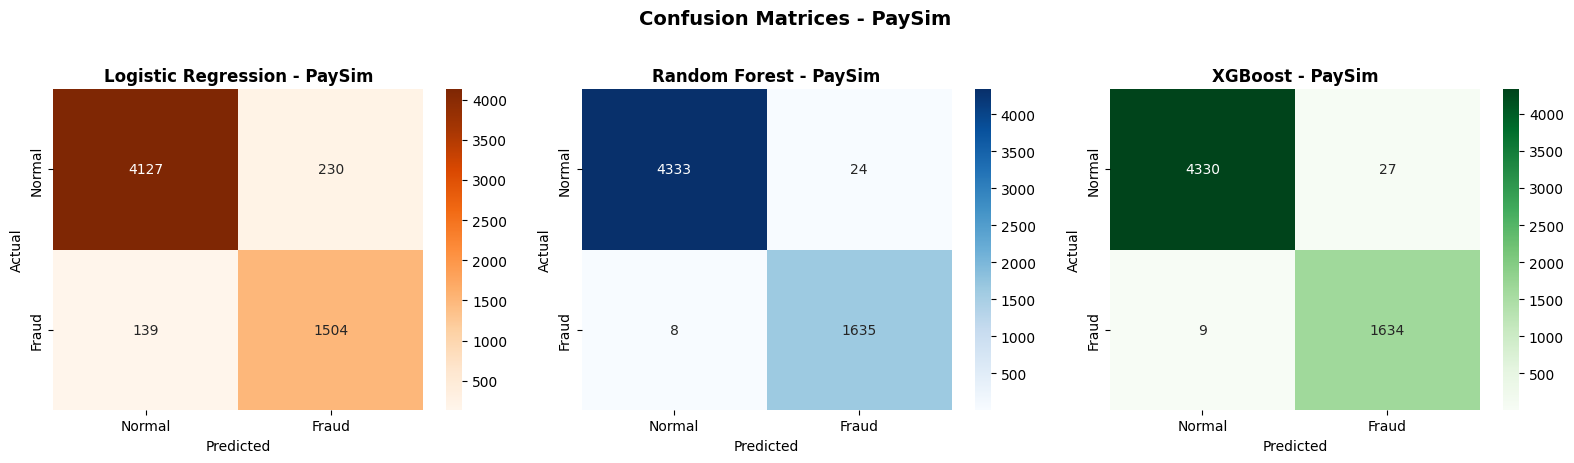

✅ Confusion Matrices saved


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ps_models = [
    (lr_ps_pred, 'Logistic Regression', 'Oranges'),
    (rf_ps_pred, 'Random Forest', 'Blues'),
    (xgb_ps_pred, 'XGBoost', 'Greens')
]
for ax, (pred, title, cmap) in zip(axes, ps_models):
    cm = confusion_matrix(y_ps_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Normal', 'Fraud'],
                yticklabels=['Normal', 'Fraud'])
    ax.set_title(f'{title} - PaySim', fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrices - PaySim', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ps_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Confusion Matrices saved')

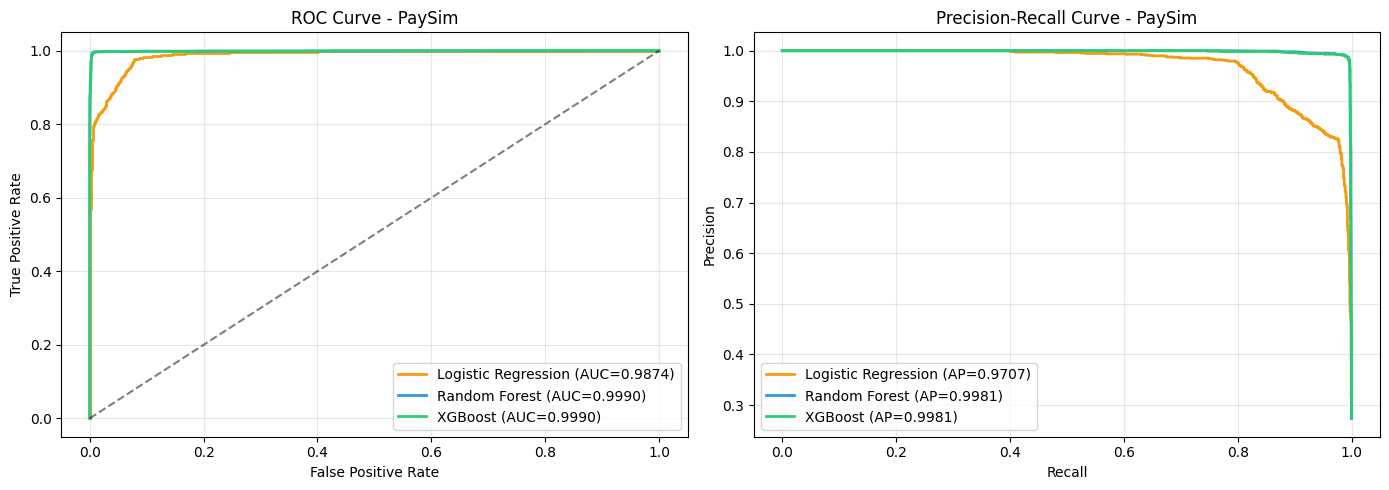

✅ ROC & PR Curves saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ps_probas = [
    (lr_ps_proba, 'Logistic Regression', '#f39c12'),
    (rf_ps_proba, 'Random Forest', '#3498db'),
    (xgb_ps_proba, 'XGBoost', '#2ecc71')
]

# ROC
ax = axes[0]
for proba, label, color in ps_probas:
    fpr, tpr, _ = roc_curve(y_ps_test, proba)
    auc = roc_auc_score(y_ps_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{label} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - PaySim')
ax.legend()
ax.grid(alpha=0.3)

# PR
ax = axes[1]
for proba, label, color in ps_probas:
    precision_vals, recall_vals, _ = precision_recall_curve(y_ps_test, proba)
    ap = average_precision_score(y_ps_test, proba)
    ax.plot(recall_vals, precision_vals, color=color, linewidth=2, label=f'{label} (AP={ap:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve - PaySim')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ps_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ ROC & PR Curves saved')

---
# ═══════════════════════════════════════════
#  PART C: Cross-Dataset Comparison
# ═══════════════════════════════════════════
> مقارنة أداء الموديلات الـ 3 على 3 datasets مختلفة:
> - IBM AML (من الـ notebook الأصلي)
> - Credit Card Fraud
> - PaySim

In [ ]:
aml_results = {
    'Logistic Regression': {'Precision': 0.7304, 'Recall': 0.8600, 'F1-Score': 0.7899, 'ROC-AUC': 0.9154, 'PR-AUC': 0.8591},
    'Random Forest':       {'Precision': 0.8938, 'Recall': 0.8250, 'F1-Score': 0.8580, 'ROC-AUC': 0.9375, 'PR-AUC': 0.9003},
    'XGBoost':             {'Precision': 0.8986, 'Recall': 0.8245, 'F1-Score': 0.8600, 'ROC-AUC': 0.9421, 'PR-AUC': 0.9044}
}


cross_data = []
for model in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    # IBM AML
    cross_data.append({
        'Dataset': 'IBM AML', 'Model': model,
        **aml_results[model]
    })
    # Credit Card
    row = cc_summary[cc_summary['Model'] == model].iloc[0]
    cross_data.append({
        'Dataset': 'Credit Card', 'Model': model,
        'Precision': row['Precision'], 'Recall': row['Recall'],
        'F1-Score': row['F1-Score'], 'ROC-AUC': row['ROC-AUC'], 'PR-AUC': row['PR-AUC']
    })
    # PaySim
    row = ps_summary[ps_summary['Model'] == model].iloc[0]
    cross_data.append({
        'Dataset': 'PaySim', 'Model': model,
        'Precision': row['Precision'], 'Recall': row['Recall'],
        'F1-Score': row['F1-Score'], 'ROC-AUC': row['ROC-AUC'], 'PR-AUC': row['PR-AUC']
    })

cross_summary = pd.DataFrame(cross_data).round(4)

print('\n' + '='*90)
print('🏆 CROSS-DATASET COMPARISON - All 3 Datasets × 3 Models')
print('='*90)
print(cross_summary.to_string(index=False))
print('='*90)


🏆 CROSS-DATASET COMPARISON - All 3 Datasets × 3 Models
    Dataset               Model  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
    IBM AML Logistic Regression     0.7304  0.8600    0.7899   0.9154  0.8591
Credit Card Logistic Regression     0.4238  0.9082    0.5779   0.9793  0.9075
     PaySim Logistic Regression     0.8674  0.9154    0.8907   0.9874  0.9707
    IBM AML       Random Forest     0.8938  0.8250    0.8580   0.9375  0.9003
Credit Card       Random Forest     0.9239  0.8673    0.8947   0.9822  0.9272
     PaySim       Random Forest     0.9855  0.9951    0.9903   0.9990  0.9981
    IBM AML             XGBoost     0.8986  0.8245    0.8600   0.9421  0.9044
Credit Card             XGBoost     0.8700  0.8878    0.8788   0.9826  0.9147
     PaySim             XGBoost     0.9837  0.9945    0.9891   0.9990  0.9981


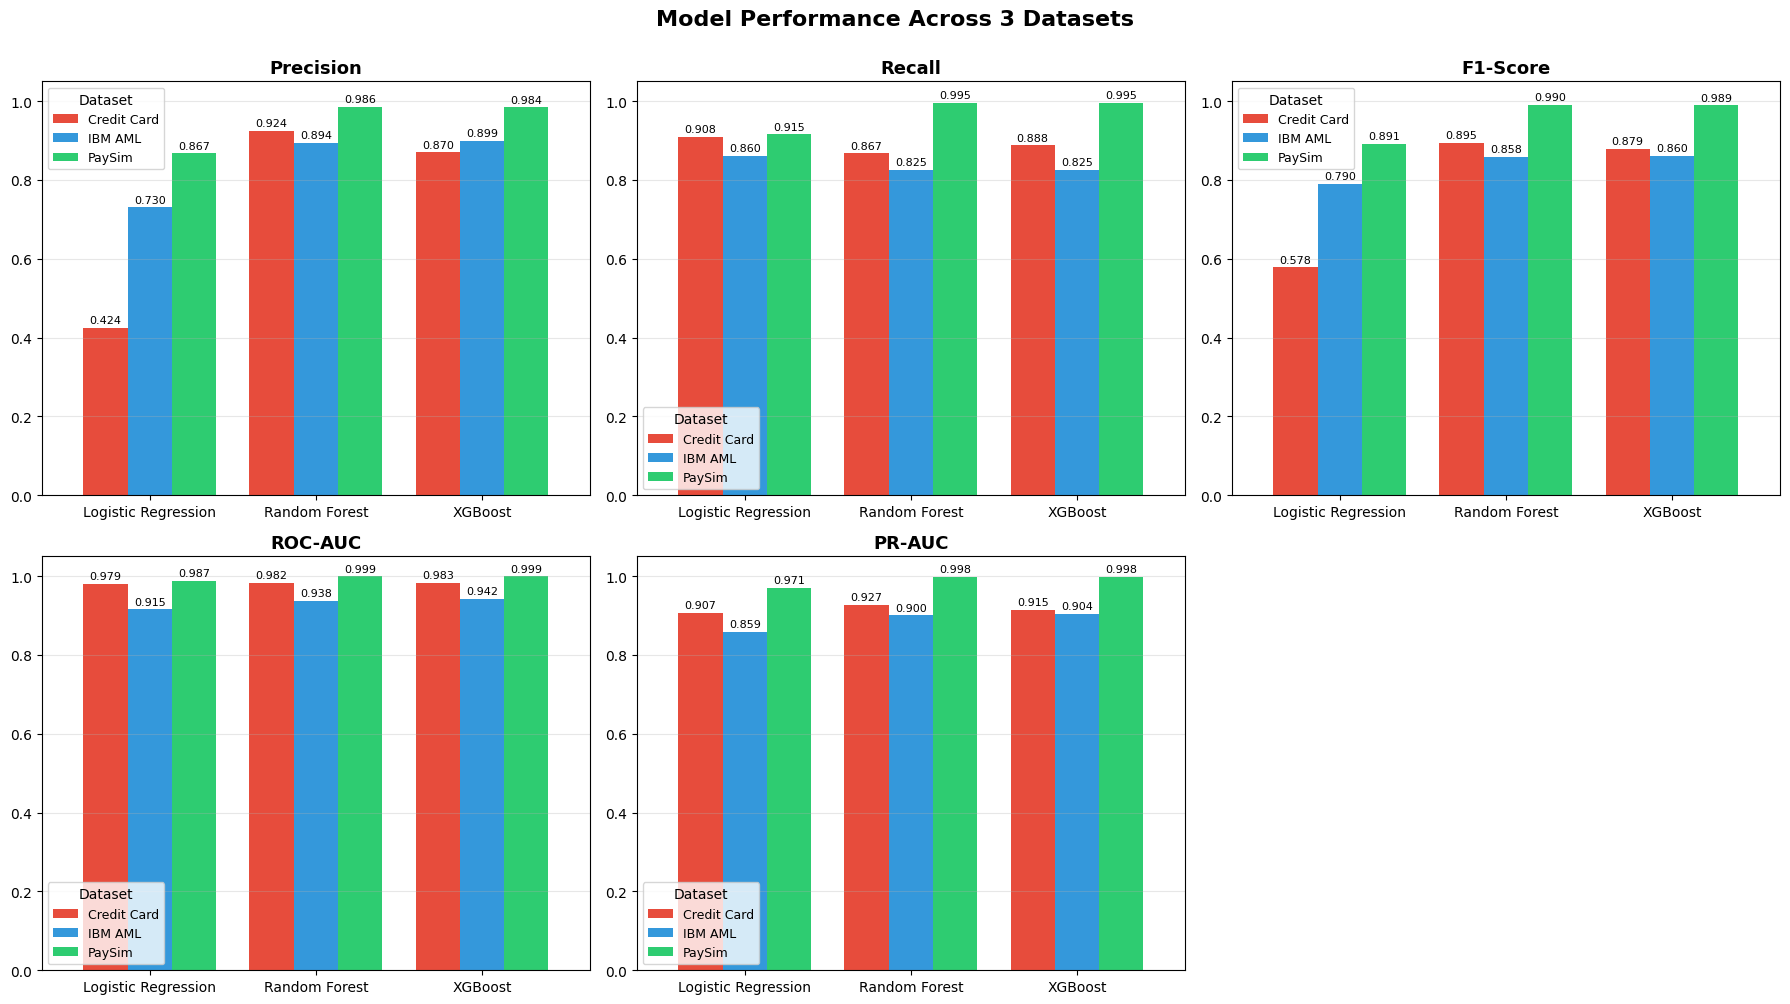

✅ Cross-Dataset Comparison saved


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics_to_plot = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']
colors = {'IBM AML': '#3498db', 'Credit Card': '#e74c3c', 'PaySim': '#2ecc71'}

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 3, idx % 3]
    pivot = cross_summary.pivot(index='Model', columns='Dataset', values=metric)
    pivot.plot(kind='bar', ax=ax, color=[colors[c] for c in pivot.columns], width=0.8)
    ax.set_title(metric, fontweight='bold', fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
    ax.set_xticklabels(pivot.index, rotation=0, ha='center')
    ax.legend(title='Dataset', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)


axes[1, 2].set_visible(False)

plt.suptitle('Model Performance Across 3 Datasets', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('cross_dataset_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Cross-Dataset Comparison saved')

In [ ]:
print('\n📊 Average Performance per Dataset:')
print('='*60)
avg_by_dataset = cross_summary.groupby('Dataset')[['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']].mean().round(4)
print(avg_by_dataset.to_string())
print('='*60)

print('\n📊 Average Performance per Model:')
print('='*60)
avg_by_model = cross_summary.groupby('Model')[['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']].mean().round(4)
print(avg_by_model.to_string())
print('='*60)


📊 Average Performance per Dataset:
             Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Dataset                                                  
Credit Card     0.7392  0.8878    0.7838   0.9814  0.9165
IBM AML         0.8409  0.8365    0.8360   0.9317  0.8879
PaySim          0.9455  0.9683    0.9567   0.9951  0.9890

📊 Average Performance per Model:
                     Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Model                                                            
Logistic Regression     0.6739  0.8945    0.7528   0.9607  0.9124
Random Forest           0.9344  0.8958    0.9143   0.9729  0.9419
XGBoost                 0.9174  0.9023    0.9093   0.9746  0.9391


---
## 💾 Save All Results

In [ ]:
# ═══════════════════════════════════════════
# 📊 PaySim: Basic vs Feature Engineering مقارنة
# ═══════════════════════════════════════════

print('=' * 70)
print('📊 PaySim — Basic Features (بدون Feature Engineering)')
print('=' * 70)
print(f'Features used: {len(PS_FEATURES)} (أصلية فقط)')
print(f'Features: {PS_FEATURES}')
print()
print('ملاحظة: قارنوا هاي النتائج مع النسخة اللي فيها Feature Engineering')
print('عشان تشوفوا تأثير الـ FE على الأداء')
print('=' * 70)


📊 PaySim — Basic Features (بدون Feature Engineering)
Features used: 10 (أصلية فقط)
Features: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

ملاحظة: قارنوا هاي النتائج مع النسخة اللي فيها Feature Engineering
عشان تشوفوا تأثير الـ FE على الأداء


In [ ]:
# Save all summaries
cc_summary.to_csv('credit_card_results.csv', index=False)
ps_summary.to_csv('paysim_results.csv', index=False)
cross_summary.to_csv('cross_dataset_results.csv', index=False)

# Save scalers
joblib.dump(scaler_cc, 'scaler_creditcard.pkl')
joblib.dump(scaler_ps, 'scaler_paysim.pkl')

print('✅ All results saved:')
print('  📁 credit_card_results.csv       — Credit Card Results')
print('  📁 paysim_results.csv            — PaySim Results')
print('  📁 cross_dataset_results.csv     — Cross-Dataset Comparison')
print('  📁 lr_creditcard_model.pkl       — LR for Credit Card')
print('  📁 rf_creditcard_model.pkl       — RF for Credit Card')
print('  📁 xgb_creditcard_model.pkl      — XGB for Credit Card')
print('  📁 lr_paysim_model.pkl           — LR for PaySim')
print('  📁 rf_paysim_model.pkl           — RF for PaySim')
print('  📁 xgb_paysim_model.pkl          — XGB for PaySim')
print('  📁 scaler_creditcard.pkl         — Credit Card Scaler')
print('  📁 scaler_paysim.pkl             — PaySim Scaler')
print('\n🏆 Done! كل الموديلات جاهزة على الـ 3 datasets')

✅ All results saved:
  📁 credit_card_results.csv       — Credit Card Results
  📁 paysim_results.csv            — PaySim Results
  📁 cross_dataset_results.csv     — Cross-Dataset Comparison
  📁 lr_creditcard_model.pkl       — LR for Credit Card
  📁 rf_creditcard_model.pkl       — RF for Credit Card
  📁 xgb_creditcard_model.pkl      — XGB for Credit Card
  📁 lr_paysim_model.pkl           — LR for PaySim
  📁 rf_paysim_model.pkl           — RF for PaySim
  📁 xgb_paysim_model.pkl          — XGB for PaySim
  📁 scaler_creditcard.pkl         — Credit Card Scaler
  📁 scaler_paysim.pkl             — PaySim Scaler

🏆 Done! كل الموديلات جاهزة على الـ 3 datasets
